In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [3]:
## LOAD GENERAL STUFF
path_fsm=r'data\FSM_all.nc'
path_snow=r'data\snow_metrics.nc'
ds_terrain = xr.open_dataset(path_fsm,decode_times=True)
ds_snow = xr.open_dataset(path_snow,decode_times=True)

altitudes = ds_terrain['dem'].values.flatten() ## On récupére les données d'altitude
aspect = ds_terrain['aspect'].values.flatten()

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(1000, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m

#primary_mask = np.ones(len(altitudes))
primary_mask = (altitudes >= 1000) & (altitudes <= 2800)
primary_mask = np.where(primary_mask,1,np.nan)


for s in range(len(ds_snow.season)) :
    curr_season = ds_snow.season[s]

    meb_peak = ds_snow["Peak_SWE"].sel(simulation='MEB_DEF', season = curr_season).values.flatten() 
    fsm_peak = ds_snow["Peak_SWE"].sel(simulation='FSM_ALL', season = curr_season).values.flatten() 
    meb_scd = ds_snow["Snow_duration"].sel(simulation='MEB_DEF', season = curr_season).values.flatten() 
    fsm_scd = ds_snow["Snow_duration"].sel(simulation='FSM_ALL', season = curr_season).values.flatten() 
    
    primary_mask = np.where(meb_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(fsm_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(meb_scd > 2, primary_mask, np.nan)
    primary_mask = np.where(fsm_scd > 2, primary_mask, np.nan)



## PEAK SWE

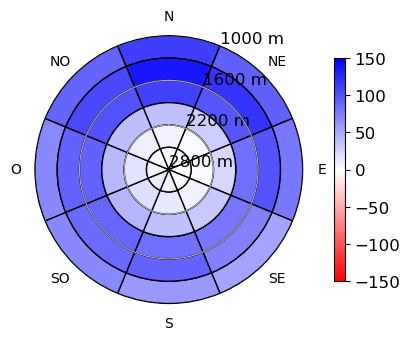

In [7]:
# COMPARISON MEB DEF - FSM ALL, ABSOLUTE
# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
SWE_matrix3 = np.zeros((len(alt)-1,len(angle)))
SWE_matrix2 = np.zeros((len(alt)-1,len(angle)))
SWE_matrix3_std = np.zeros((len(alt)-1,len(angle)))
SWE_matrix2_std = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["Peak_SWE"].sel(simulation='MEB_DEF').mean(dim="season", skipna=True).values.flatten() - ds_snow["Peak_SWE"].sel(simulation='FSM_ALL').mean(dim="season", skipna=True).values.flatten() 
variable2 = ds_snow["Peak_SWE"].sel(simulation='FSM_ALL').mean(dim="season", skipna=True).values.flatten() 
variable3 = ds_snow["Peak_SWE"].sel(simulation='MEB_DEF').mean(dim="season", skipna=True).values.flatten() 
variable = np.where(primary_mask ==1 ,variable,np.nan)
variable2 = np.where(primary_mask ==1 ,variable2,np.nan)
variable3 = np.where(primary_mask ==1 ,variable3,np.nan)


for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]))
            
        SWE_values = variable[mask]
        SWE_values2 = variable2[mask]
        SWE_values3= variable3[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        
        SWE_matrix2[i, j] = np.nanmean(SWE_values2) if SWE_values2.size > 0 else np.nan 
        SWE_matrix2_std[i, j] = np.nanstd(SWE_values2) if SWE_values2.size > 0 else np.nan

        SWE_matrix3[i, j] = np.nanmean(SWE_values3) if SWE_values3.size > 0 else np.nan 
        SWE_matrix3_std[i, j] = np.nanstd(SWE_values3) if SWE_values3.size > 0 else np.nan
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-150,vmax=150)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-150,150)

peakswe_mean_MEBD_FSMA_abs = SWE_matrix

In [17]:
# Average discrepancies for numbers in paper
peakswe_mean_MEBD_FSMA_abs.mean()/SWE_matrix2.mean()
np.nanmean(variable)/np.nanmean(variable2)

np.float64(0.12678961552061202)

In [28]:
# coefficients of variation
cv_fsm =     np.divide(SWE_matrix2_std,SWE_matrix2)
cv_meb =     np.divide(SWE_matrix3_std,SWE_matrix3)
cv_fsm.mean()

np.float64(0.32015833088302464)

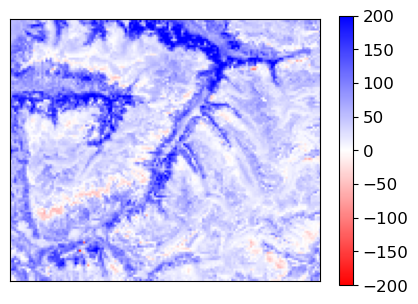

In [8]:
# PEAK SWE MAP INSET
variable = ds_snow["Peak_SWE"].sel(simulation='MEB_DEF', season = '2020/2021').values - ds_snow["Peak_SWE"].sel(simulation='FSM_ALL', season = '2020/2021').values
#plt.imshow(variable, aspect='equal', origin = 'lower', cmap = 'bwr_r', vmin = -200, vmax = 200)
#plt.colorbar(labelsize=12)



fig, ax = plt.subplots(figsize=(5, 3.5))

# Plot the array as an image
im = ax.imshow(variable, cmap='bwr_r', vmin = -200, vmax = 200, origin='lower')

# Add colorbar
cbar = fig.colorbar(im, ax=ax)

# Control colorbar tick label size
cbar.ax.tick_params(labelsize=12)
ax.set_xticks([])
ax.set_yticks([])
ax.set_aspect('equal')
# Control axis tick label size
#ax.tick_params(axis='both', labelsize=12)


In [17]:
np.percentile(variable,1)

np.float64(-24.707906528947053)

## SNOW COVER DURATION

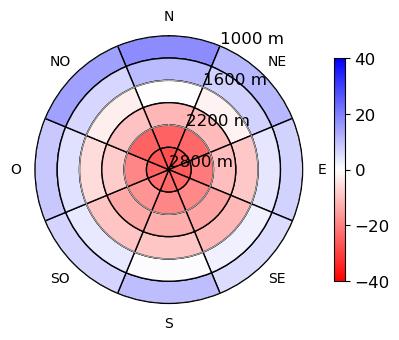

In [7]:
# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
SWE_matrix2 = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["Snow_duration"].sel(simulation='MEB_DEF').mean(dim="season", skipna=True).values.flatten() - ds_snow["Snow_duration"].sel(simulation='FSM_ALL').mean(dim="season", skipna=True).values.flatten() 
variable2 = ds_snow["Snow_duration"].sel(simulation='FSM_ALL').mean(dim="season", skipna=True).values.flatten() 

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]))
            
        SWE_values = variable[mask]
        SWE_values2 = variable2[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        SWE_matrix2[i, j] = np.nanmean(SWE_values2) if SWE_values2.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-40,vmax=40)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
unite = 'days'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-40,40)


In [ ]:
# average differences 
np.nanmean(variable)

np.float64(-11.350788408267633)

C:\Users\mazzottg\AppData\Local\Temp\ipykernel_916\3607505817.py:3: RuntimeWarning: invalid value encountered in subtract
  variable = ds_snow["Ablation_rate"].sel(simulation='MEB_DEF').mean(dim="season", skipna=True).values.flatten() - ds_snow["Ablation_rate"].sel(simulation='FSM_ALL').mean(dim="season", skipna=True).values.flatten()


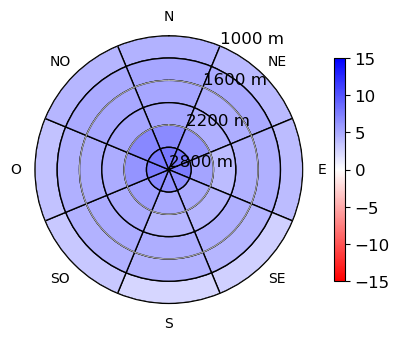

In [10]:


# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["Ablation_rate"].sel(simulation='MEB_DEF').mean(dim="season", skipna=True).values.flatten() - ds_snow["Ablation_rate"].sel(simulation='FSM_ALL').mean(dim="season", skipna=True).values.flatten() 
variable = np.where(np.isfinite(variable), variable, np.nan)

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-15,vmax=15)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200,1600,1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
unite = 'mm/d'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-15,15)


In [12]:
np.mean(SWE_matrix)
np.nanmean(variable)

np.float64(5.483611778538547)

In [9]:
# TIME SERIES ANALYSES
path_fsm=r'data\FSM_all_corr.nc'
path_meb=r'data\MEBCro_def.nc'

ds_fsm = xr.open_dataset(path_fsm,decode_times=True)
ds_meb = xr.open_dataset(path_meb,decode_times=True)

Text(0.04, 0.5, 'SWE [mm]')

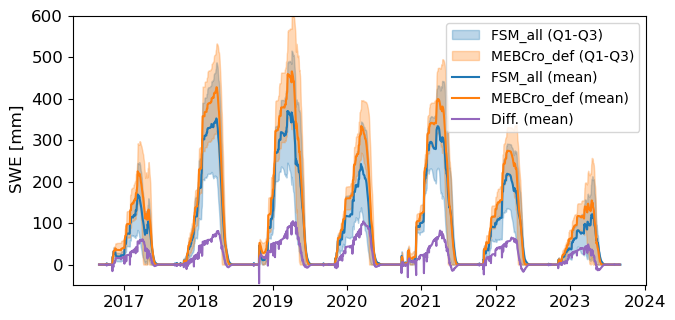

In [15]:
# time series for specific elevation band - FSM-ALL vs. MEB-DEF -- FIGURE 3
mask = ((ds_fsm['dem'] >= 1300) & (ds_fsm['dem'] <= 2200))
masked_data_fsm = ds_fsm["swet_all_corr"].where(mask)
masked_data_meb = ds_meb["swet_all"].where(mask)
masked_data_diff = masked_data_meb - masked_data_fsm

# Compute quantiles for FSM and MEB
q25_fsm = masked_data_fsm.quantile(0.25, dim=['yy', 'xx'])
q75_fsm = masked_data_fsm.quantile(0.75, dim=['yy', 'xx'])
q25_meb = masked_data_meb.quantile(0.25, dim=['yy', 'xx'])
q75_meb = masked_data_meb.quantile(0.75, dim=['yy', 'xx'])

q05_fsm = masked_data_fsm.quantile(0.05, dim=['yy', 'xx'])
q95_fsm = masked_data_fsm.quantile(0.95, dim=['yy', 'xx'])
q05_meb = masked_data_meb.quantile(0.05, dim=['yy', 'xx'])
q95_meb = masked_data_meb.quantile(0.95, dim=['yy', 'xx'])

q50_fsm = masked_data_fsm.quantile(0.50, dim=['yy', 'xx'])
q50_meb = masked_data_meb.quantile(0.50, dim=['yy', 'xx'])

mean_fsm = masked_data_fsm.mean(dim=("yy", "xx"), skipna=True)
mean_meb = masked_data_meb.mean(dim=("yy", "xx"), skipna=True)
mean_diff = masked_data_diff.mean(dim=("yy", "xx"), skipna=True)

min_fsm = masked_data_fsm.min(dim=("yy", "xx"), skipna=True)
min_meb = masked_data_meb.min(dim=("yy", "xx"), skipna=True)

max_fsm = masked_data_fsm.max(dim=("yy", "xx"), skipna=True)
max_meb = masked_data_meb.max(dim=("yy", "xx"), skipna=True)

# Extract time axis
time_fsm = q25_fsm['time'].values
time_meb = q25_meb['time'].values

# Plot using matplotlib
fig, ax = plt.subplots(1, 1, figsize=(7.4, 3.5), sharex=True)

# Plot quantile envelopes
ax.fill_between(time_fsm, q25_fsm.values, q75_fsm.values, alpha=0.3, color='tab:blue', label='FSM_all (Q1-Q3)')
ax.fill_between(time_meb, q25_meb.values, q75_meb.values, alpha=0.3, color='tab:orange', label='MEBCro_def (Q1-Q3)')

ax.plot(time_fsm, mean_fsm.values, color='tab:blue', linewidth=1.5, label='FSM_all (mean)')
ax.plot(time_meb, mean_meb.values, color='tab:orange', linewidth=1.5, label='MEBCro_def (mean)')
ax.plot(time_meb, mean_diff.values, color='tab:purple', linewidth=1.5, label='Diff. (mean)')


ax.legend()
ax.tick_params(labelsize=12)
ax.set_ylim(-50,600)
#ax.set_xticklabels(fontsize=12)
#ax.set_yticklabels(lafontsize=12)

fig.text(0.04, 0.5, 'SWE [mm]', va='center', rotation='vertical',fontsize = 12)

# plt.tight_layout(rect=[0.05, 0, 1, 1])
# plt.savefig(f'figs/swe_ts_lai_classes.png', dpi=300, bbox_inches='tight')

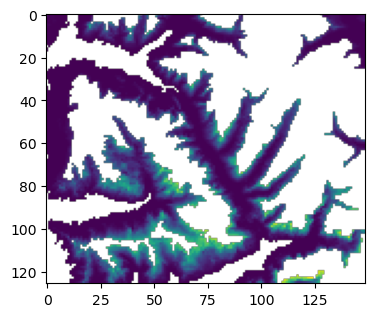

In [8]:
testfig = masked_data_fsm.isel(time=1000)

fig, ax = plt.subplots(figsize=(5, 3.5))

# Plot the array as an image
im = ax.imshow(testfig)

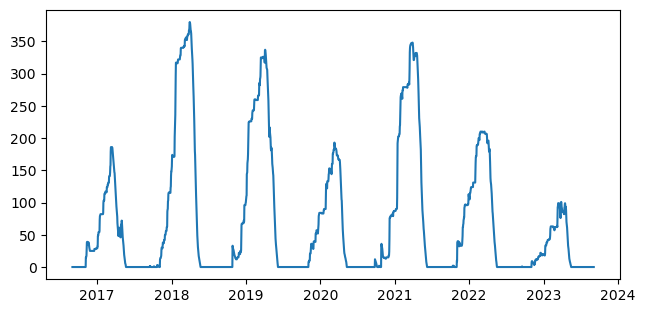

In [10]:
testpoint = masked_data_fsm.isel(xx=50,yy=125 )

fig, ax = plt.subplots(1, 1, figsize=(7.4, 3.5), sharex=True)
ax.plot(time_fsm, testpoint.values, color='tab:blue', linewidth=1.5, label='FSM_all (mean)')

NameError: name 'time_fsm' is not defined

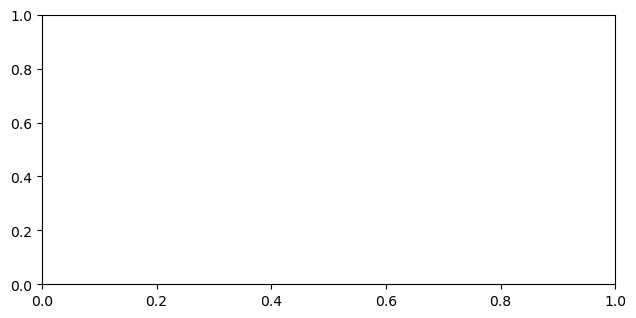

In [6]:
# Plot using matplotlib
fig, ax = plt.subplots(1, 1, figsize=(7.4, 3.5), sharex=True)

# Plot quantile envelopes
ax.fill_between(time_fsm, q05_fsm.values, q95_fsm.values, alpha=0.3, color='tab:blue', label='FSM_all (Q1-Q3)')
ax.fill_between(time_meb, q05_meb.values, q95_meb.values, alpha=0.3, color='tab:orange', label='MEBCro_def (Q1-Q3)')

ax.plot(time_fsm, mean_fsm.values, color='tab:blue', linewidth=1.5, label='FSM_all (mean)')
ax.plot(time_meb, mean_meb.values, color='tab:orange', linewidth=1.5, label='MEBCro_def (mean)')

#ax.legend()
ax.tick_params(labelsize=12)
ax.set_ylim(0,800)
#ax.set_xticklabels(fontsize=12)
#ax.set_yticklabels(lafontsize=12)

fig.text(0.04, 0.5, 'SWE [mm]', va='center', rotation='vertical',fontsize = 12)

Text(0.04, 0.5, 'SWE [mm]')

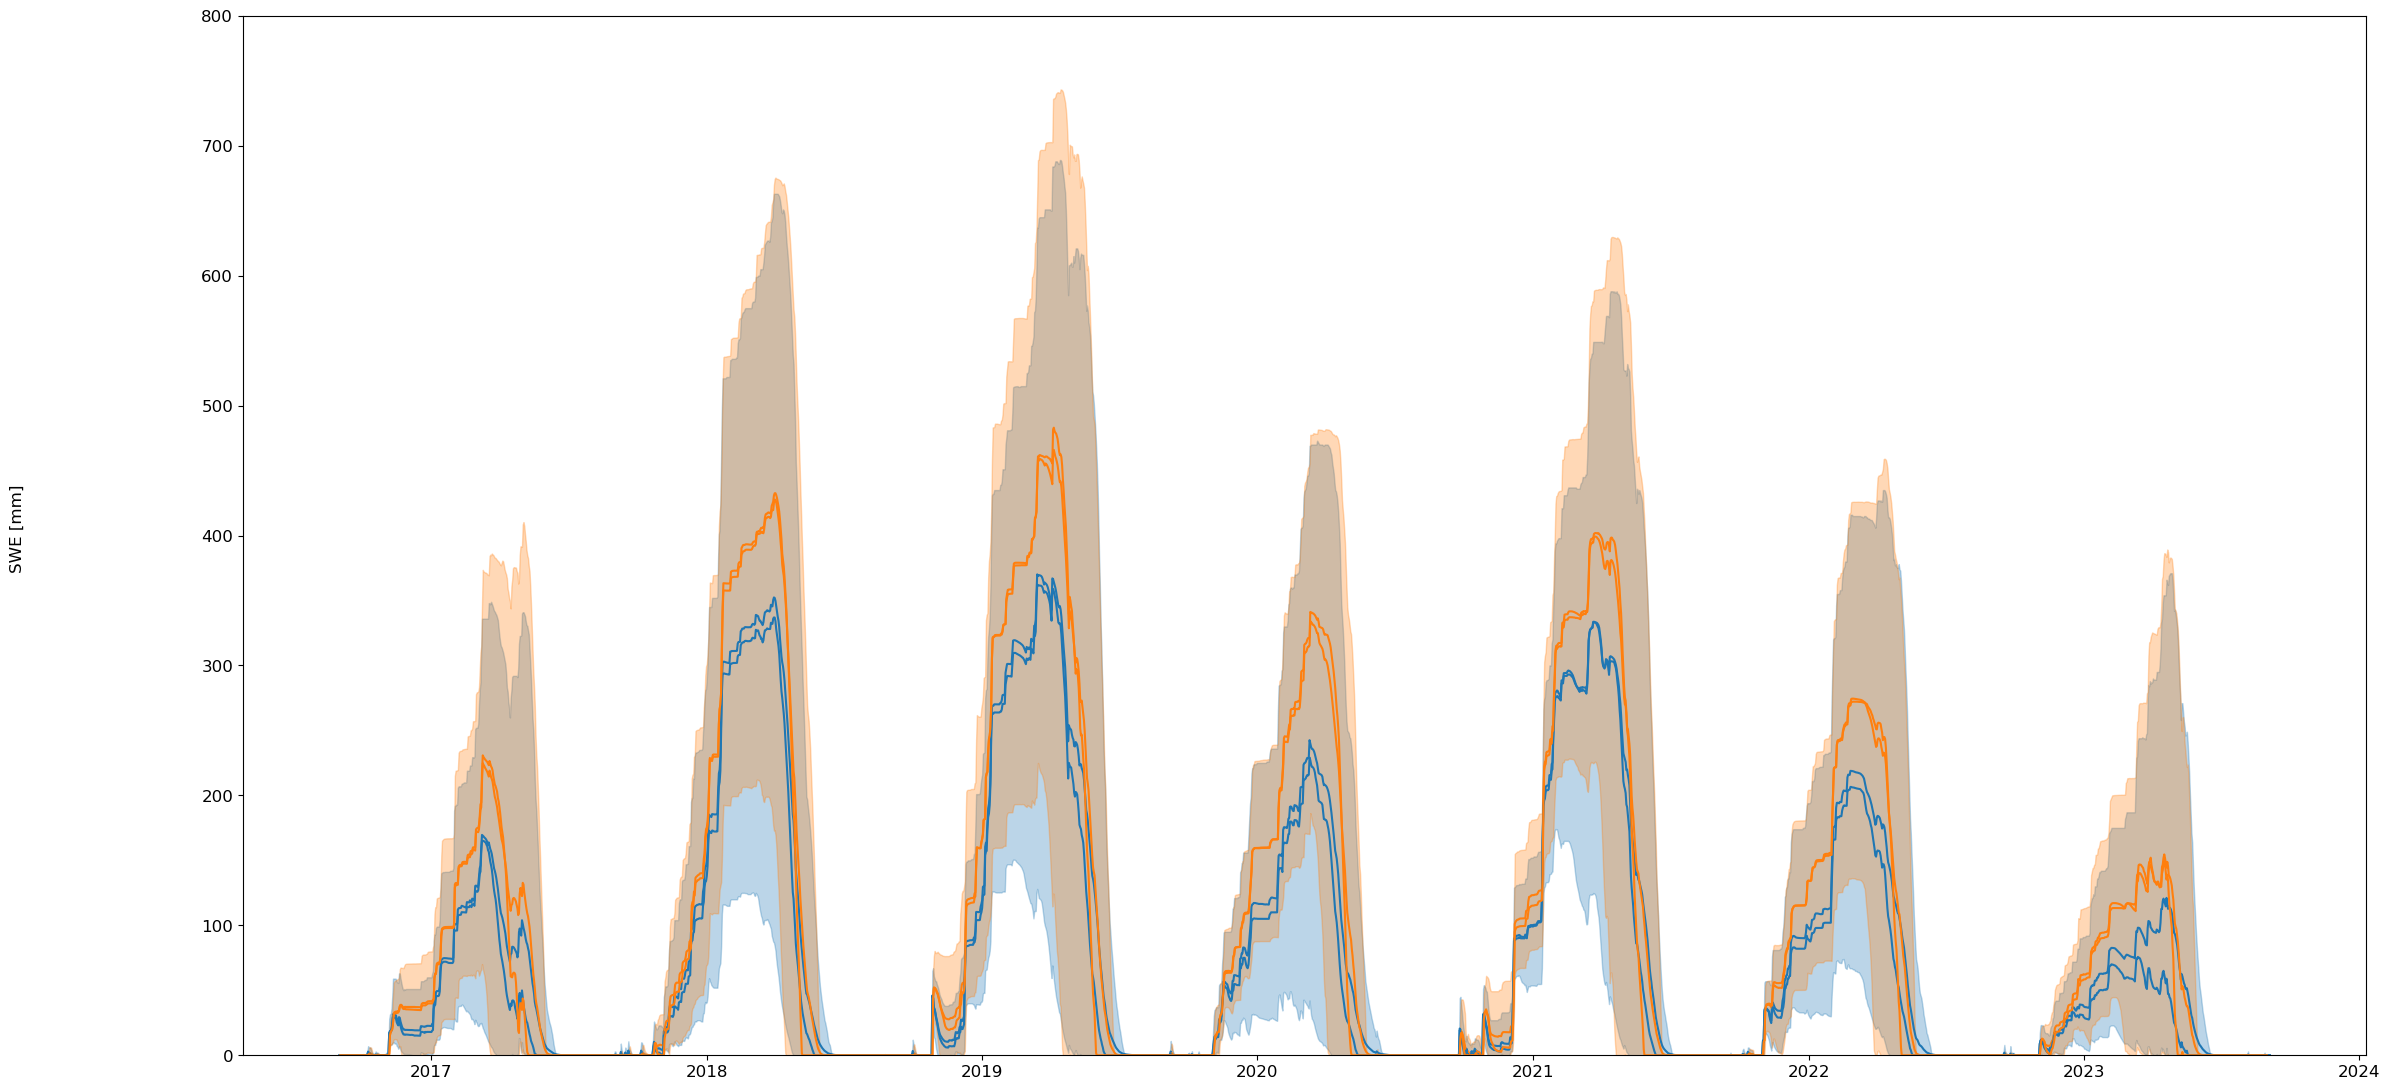

In [11]:
# Plot using matplotlib
fig, ax = plt.subplots(1, 1, figsize=(27.4, 13.5), sharex=True)

# Plot quantile envelopes
ax.fill_between(time_fsm, q05_fsm.values, q95_fsm.values, alpha=0.3, color='tab:blue', label='FSM_all (Q1-Q3)')
ax.fill_between(time_meb, q05_meb.values, q95_meb.values, alpha=0.3, color='tab:orange', label='MEBCro_def (Q1-Q3)')


ax.plot(time_fsm, mean_fsm.values, color='tab:blue', linewidth=1.5, label='FSM_all (mean)')
ax.plot(time_meb, mean_meb.values, color='tab:orange', linewidth=1.5, label='MEBCro_def (mean)')

ax.plot(time_fsm, q50_fsm.values, color='tab:blue', linewidth=1.5, label='FSM_all (mean)')
ax.plot(time_meb, q50_meb.values, color='tab:orange', linewidth=1.5, label='MEBCro_def (mean)')

#ax.legend()
ax.tick_params(labelsize=12)
ax.set_ylim(0,800)
#ax.set_xticklabels(fontsize=12)
#ax.set_yticklabels(lafontsize=12)

fig.text(0.04, 0.5, 'SWE [mm]', va='center', rotation='vertical',fontsize = 12)

In [ ]:
# CORRELATION COEFFICIENTS
path_fsm=r'data\FSM_all.nc'
path_eco='data/ECOCLIM_surf.nc'
path_snow=r'data\snow_metrics.nc'
ds_fsm = xr.open_dataset(path_fsm,decode_times=True)
ds_snow = xr.open_dataset(path_snow,decode_times=True)
ds_meb=xr.open_dataset(path_eco)

xx,yy=ds_fsm.xx.values,ds_fsm.yy.values
latitude,longitude=ds_fsm.xx,ds_fsm.yy
X, Y = np.meshgrid(latitude, longitude)
h_veg=ds_meb.H_VEG.values.reshape(len(yy),len(xx))
LAI=ds_meb.LAI.values.reshape(len(yy),len(xx))
vegtype1=ds_meb.VEGTYPE1.values.reshape(len(yy),len(xx))
ds_meb=ds_meb.assign_coords(  ## on rajoute ces trois variables mais reshaper pour que ça matche avec fsm 
xx=('xx',xx), 
yy=('yy',yy)
)
ds_meb['lai']=(('yy','xx'),LAI)
ds_meb['h_veg']=(('yy','xx'),h_veg)
ds_meb['vegtype1']=(('yy','xx'),vegtype1)


In [ ]:
lai_diff = np.nan_to_num(ds_meb['lai'].values)-ds_fsm['lai'].values
mask = ds_fsm['forest'].values.flatten() >= 0.1
cor_coefs = np.zeros(len(ds_snow.season))
for s in range(len(ds_snow.season)) :
    curr_season = ds_snow.season[s]
    vegdata=lai_diff.flatten()[mask]
    snowvariable = ds_snow["Peak_SWE"].sel(simulation='MEB_DEF',season=curr_season).values.flatten()[mask] - ds_snow["Peak_SWE"].sel(simulation='FSM_ALL',season= curr_season).values.flatten()[mask] 
    plt.scatter(vegdata,snowvariable,s=2)
    
    cc = np.corrcoef(vegdata,snowvariable,rowvar=False)
    cor_coefs[s] = cc[0,1]


In [ ]:
cor_coefs.mean()